# Entrega 3 · Modelo predictivo de siniestros graves por localidad y mes
**Proyecto BI — Seguridad vial en Bogotá (equipo 506241154)**

**Pregunta de negocio (BA):** ¿Cuántos siniestros graves (con heridos o fallecidos) habrá en cada localidad el próximo mes, para decidir dónde reforzar control y señalización?

- **Tipo de problema:** regresión.
- **Variable objetivo:** `siniestros_graves` (siniestros con heridos o fallecidos) por localidad y mes.
- **Métrica:** MAE (error absoluto medio) y RMSE, medidos sobre el periodo de prueba.
- **Datos:** `modelo/datos_modelo.csv`, generado con `modelo/extraccion.sql` sobre el data warehouse `dw_siniestros`.

**Cómo ejecutarlo:** en Colab, subir `datos_modelo.csv` (o clonar el repositorio) y usar *Entorno de ejecución → Ejecutar todo*. En local: `pip install -r requirements.txt` y abrir el cuaderno. Por defecto lee el CSV; los bloques que hablan con el data warehouse solo se activan con variables de entorno (la contraseña nunca va en el código).

## 1. Librerías y configuración

In [1]:
import os
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestRegressor
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder

warnings.filterwarnings("ignore")
pd.set_option("display.width", 140)
pd.set_option("display.max_columns", 30)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

SEMILLA = 42                 # reproducibilidad
UMBRAL_MAE = 5.0             # criterio de exito (seccion 1.3): MAE < 5 siniestros graves por localidad y mes
INICIO_PRUEBA = pd.Timestamp("2020-07-01")   # prueba = ultimos 6 meses disponibles (jul-dic 2020)

def ubicar(nombre):
    """Busca un archivo del proyecto en las carpetas habituales (local o Colab)."""
    for base in [Path("."), Path("modelo"), Path(".."), Path("../modelo"), Path("/content"), Path("/content/modelo"),
                 Path("/content/bi-proyecto-equipo506241154/modelo")]:
        if (base / nombre).exists():
            return (base / nombre).resolve()
    return None

ruta_csv = ubicar("datos_modelo.csv")
if ruta_csv is None:
    try:                                         # Colab: pedir el archivo al usuario
        from google.colab import files
        files.upload()
        ruta_csv = ubicar("datos_modelo.csv")
    except ImportError:
        pass
assert ruta_csv is not None, "No se encontro datos_modelo.csv: ponerlo junto al cuaderno o en modelo/"

CARPETA_MODELO = ruta_csv.parent
RAIZ = CARPETA_MODELO.parent if CARPETA_MODELO.name == "modelo" else CARPETA_MODELO
CARPETA_FIG = CARPETA_MODELO / "figuras"
CARPETA_FIG.mkdir(exist_ok=True)
CARPETA_DDL = RAIZ / "dw" / "ddl" if (RAIZ / "dw" / "ddl").exists() else CARPETA_MODELO
print("Datos:", ruta_csv.parent.name + "/" + ruta_csv.name)
print("Figuras en:", CARPETA_FIG.parent.name + "/" + CARPETA_FIG.name)

Datos: modelo/datos_modelo.csv
Figuras en: modelo/figuras


## 2. Comprensión de los datos
### 2.1 Extracción
Por defecto se lee `datos_modelo.csv`, que es el resultado de `modelo/extraccion.sql` (una fila por localidad y mes, con ceros en los meses sin siniestros). Si se define `USAR_DW=1` junto con `DW_USER` y `DW_PASSWORD` (y opcionalmente `DW_HOST`, `DW_PORT`, `DW_DB`), el cuaderno ejecuta la consulta directamente sobre el data warehouse con SQLAlchemy.

In [2]:
if os.getenv("USAR_DW") == "1":
    from sqlalchemy import create_engine, text
    from sqlalchemy.engine import URL
    url = URL.create("mysql+pymysql",
                     username=os.environ["DW_USER"], password=os.environ["DW_PASSWORD"],
                     host=os.getenv("DW_HOST", "localhost"), port=int(os.getenv("DW_PORT", "3306")),
                     database=os.getenv("DW_DB", "dw_siniestros"))
    motor = create_engine(url)
    consulta = (CARPETA_MODELO / "extraccion.sql").read_text(encoding="utf-8")
    df_bruto = pd.read_sql(text(consulta), motor)
    print("Datos leidos del data warehouse:", df_bruto.shape)
else:
    df_bruto = pd.read_csv(ruta_csv)
    print("Datos leidos del CSV:", df_bruto.shape)

df_bruto.head()

Datos leidos del CSV: (756, 6)


,localidad,anio,mes,siniestros_total,siniestros_graves,fatales
0,ANTONIO NARINO,2018,1,20,10,1
1,ANTONIO NARINO,2018,2,27,11,1
2,ANTONIO NARINO,2018,3,32,19,0
3,ANTONIO NARINO,2018,4,24,11,1
4,ANTONIO NARINO,2018,5,37,24,0


### 2.2 Descripción del conjunto de datos

In [3]:
print("Filas, columnas:", df_bruto.shape)
print("Localidades:", df_bruto["localidad"].nunique(), "| Periodo:", f'{df_bruto["anio"].min()}-{df_bruto["mes"].min():02d}',
      "a", f'{df_bruto["anio"].max()}-{df_bruto["mes"].max():02d}')
print("\nTipos de dato:")
print(df_bruto.dtypes)
print("\nNulos por columna:")
print(df_bruto.isna().sum())
df_bruto.describe().round(2)

Filas, columnas: (756, 6)
Localidades: 21 | Periodo: 2018-01 a 2020-12

Tipos de dato:
localidad            object
anio                  int64
mes                   int64
siniestros_total      int64
siniestros_graves     int64
fatales               int64
dtype: object

Nulos por columna:
localidad            0
anio                 0
mes                  0
siniestros_total     0
siniestros_graves    0
fatales              0
dtype: int64


,anio,mes,siniestros_total,siniestros_graves,fatales
count,756.00,756.00,756.00,756.00,756.00
mean,2019.00,6.50,66.14,24.44,1.04
std,0.82,3.45,51.79,17.97,1.20
min,2018.00,1.00,0.00,0.00,0.00
25%,2018.00,3.75,29.00,13.00,0.00
50%,2019.00,6.50,51.00,21.00,1.00
75%,2020.00,9.25,98.00,33.00,2.00
max,2020.00,12.00,217.00,96.00,6.00


### 2.3 Distribución de la variable objetivo

Minimo 0 | mediana 21 | media 24.4 | maximo 96 | desv. estandar 18.0
Q1 13 | Q3 33 | valla de atipicos (Q3 + 1,5 IQR) 63 | registros por encima: 30
Registros con 0 graves: 70


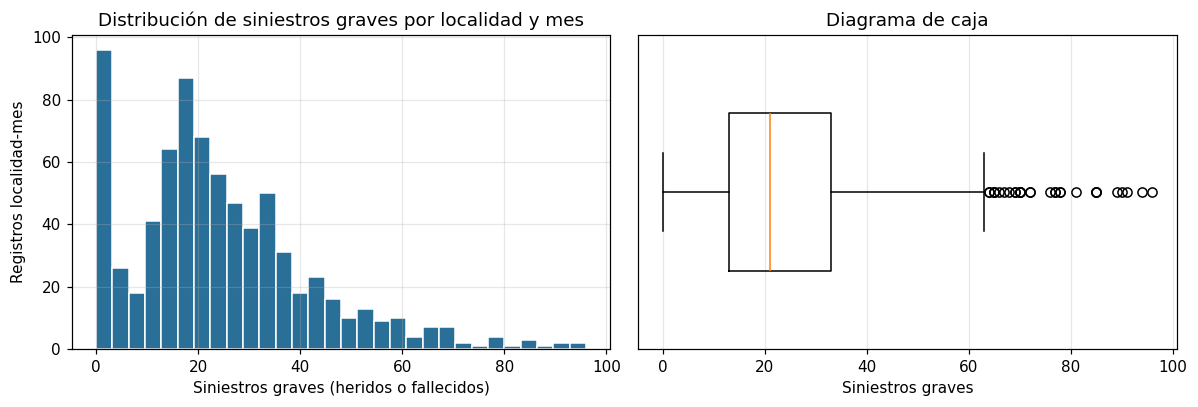

In [4]:
y = df_bruto["siniestros_graves"]
q1, q3 = y.quantile([0.25, 0.75])
valla = q3 + 1.5 * (q3 - q1)
print(f"Minimo {y.min()} | mediana {y.median():.0f} | media {y.mean():.1f} | maximo {y.max()} | desv. estandar {y.std():.1f}")
print(f"Q1 {q1:.0f} | Q3 {q3:.0f} | valla de atipicos (Q3 + 1,5 IQR) {valla:.0f} | registros por encima: {(y > valla).sum()}")
print(f"Registros con 0 graves: {(y == 0).sum()}")

fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
ax[0].hist(y, bins=30, color="#2a6f97", edgecolor="white")
ax[0].set_title("Distribución de siniestros graves por localidad y mes")
ax[0].set_xlabel("Siniestros graves (heridos o fallecidos)"); ax[0].set_ylabel("Registros localidad-mes")
ax[1].boxplot(y, vert=False, widths=0.5)
ax[1].set_title("Diagrama de caja"); ax[1].set_xlabel("Siniestros graves"); ax[1].set_yticks([])
plt.tight_layout(); plt.savefig(CARPETA_FIG / "fig_2_3_distribucion_objetivo.png", dpi=150); plt.show()

**Lectura.** La distribución es asimétrica a la derecha: la mayoría de los registros localidad-mes tiene pocos siniestros graves y unas pocas localidades grandes (sobre todo Kennedy) producen los valores altos. Los valores sobre la valla de atípicos corresponden a localidades de mucho tráfico, no a errores de captura, por eso se conservan (ver sección 3). Hay meses con cero siniestros graves solo en localidades casi sin registros (Candelaria, Sumapaz y la categoría «Desconocida»).

### 2.4 Análisis exploratorio (tres gráficos)

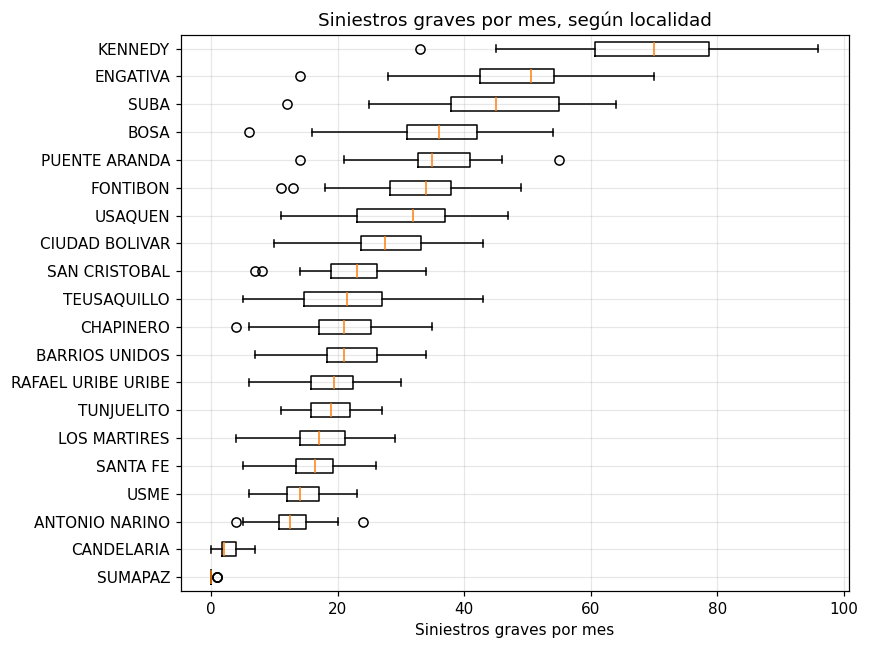

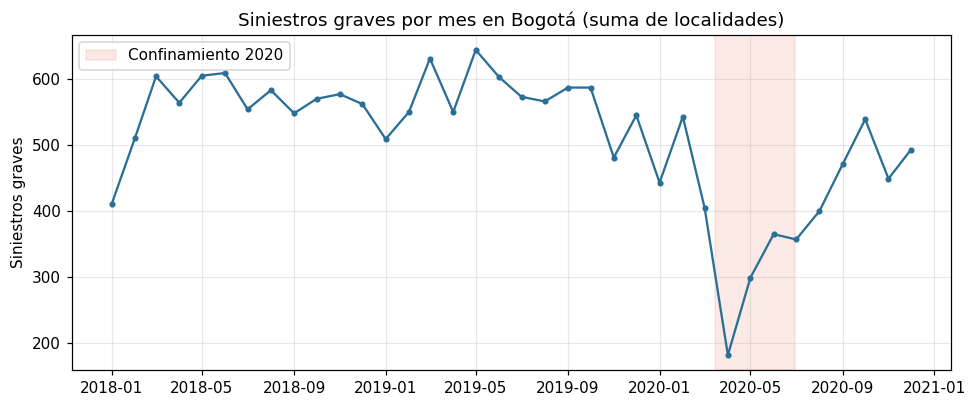

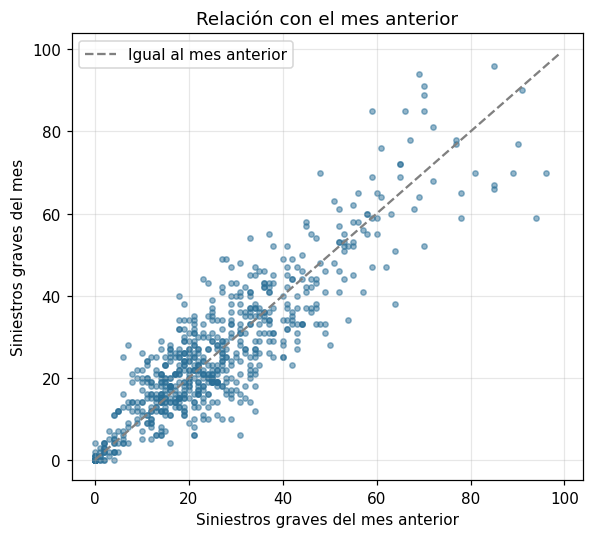

Correlacion graves vs mes anterior: 0.892
Correlacion graves vs promedio 3 meses previos: 0.917


In [5]:
def agregar_derivadas(d):
    """Variables que se conocen ANTES de predecir el mes t: solo usan meses anteriores."""
    d = d.copy()
    d["fecha"] = pd.to_datetime(dict(year=d["anio"], month=d["mes"], day=1))
    d = d.sort_values(["localidad", "fecha"]).reset_index(drop=True)
    g = d.groupby("localidad")
    d["graves_mes_anterior"] = g["siniestros_graves"].shift(1)
    d["graves_prom_3m"] = g["siniestros_graves"].transform(lambda s: s.shift(1).rolling(3).mean())
    d["total_mes_anterior"] = g["siniestros_total"].shift(1)
    return d

exp = agregar_derivadas(df_bruto[df_bruto["localidad"] != "DESCONOCIDA"])

# Grafico 1: graves por localidad
orden = exp.groupby("localidad")["siniestros_graves"].median().sort_values().index
fig, ax = plt.subplots(figsize=(8, 6))
ax.boxplot([exp.loc[exp["localidad"] == l, "siniestros_graves"] for l in orden], vert=False)
ax.set_yticklabels(list(orden))
ax.set_title("Siniestros graves por mes, según localidad"); ax.set_xlabel("Siniestros graves por mes")
plt.tight_layout(); plt.savefig(CARPETA_FIG / "fig_2_4_a_graves_por_localidad.png", dpi=150); plt.show()

# Grafico 2: serie mensual del total de Bogota
serie = exp.groupby("fecha")["siniestros_graves"].sum()
fig, ax = plt.subplots(figsize=(9, 3.8))
ax.plot(serie.index, serie.values, marker="o", ms=3, color="#2a6f97")
ax.axvspan(pd.Timestamp("2020-03-15"), pd.Timestamp("2020-06-30"), color="#e76f51", alpha=0.15, label="Confinamiento 2020")
ax.set_title("Siniestros graves por mes en Bogotá (suma de localidades)"); ax.set_ylabel("Siniestros graves"); ax.legend()
plt.tight_layout(); plt.savefig(CARPETA_FIG / "fig_2_4_b_serie_mensual.png", dpi=150); plt.show()

# Grafico 3: mes anterior vs mes actual
ok = exp.dropna(subset=["graves_mes_anterior"])
fig, ax = plt.subplots(figsize=(5.5, 5))
ax.scatter(ok["graves_mes_anterior"], ok["siniestros_graves"], s=12, alpha=0.5, color="#2a6f97")
lim = [0, max(ok["graves_mes_anterior"].max(), ok["siniestros_graves"].max()) + 3]
ax.plot(lim, lim, "--", color="gray", label="Igual al mes anterior")
ax.set_xlabel("Siniestros graves del mes anterior"); ax.set_ylabel("Siniestros graves del mes")
ax.set_title("Relación con el mes anterior"); ax.legend()
plt.tight_layout(); plt.savefig(CARPETA_FIG / "fig_2_4_c_mes_anterior_vs_actual.png", dpi=150); plt.show()
print("Correlacion graves vs mes anterior:", round(ok["graves_mes_anterior"].corr(ok["siniestros_graves"]), 3))
print("Correlacion graves vs promedio 3 meses previos:", round(exp.dropna(subset=["graves_prom_3m"])[["graves_prom_3m", "siniestros_graves"]].corr().iloc[0, 1], 3))

**Lectura de los gráficos.**
1. *Por localidad:* el nivel de siniestros graves depende sobre todo de la localidad (Kennedy, Engativá y Suba lideran); por eso la localidad entra como variable.
2. *Serie mensual:* el total de Bogotá se mantiene entre unos 480 y 650 por mes en 2018-2019 y cae de forma brusca durante el confinamiento de 2020 (abril-junio), con recuperación parcial después. Esto es un cambio de régimen que ningún modelo entrenado solo con 2018-2019 podría anticipar.
3. *Mes anterior vs mes actual:* los puntos se alinean alrededor de la diagonal; lo que pasó el mes pasado en una localidad anticipa lo que pasará este mes. De ahí salen las variables derivadas de la sección 3.

## 3. Preparación de los datos
Cada tratamiento queda con el número de registros afectados para la tabla 3.1 del documento.

In [6]:
n_inicial = len(df_bruto)
n_nulos = int(df_bruto.isna().sum().sum())

# (a) Categoria "DESCONOCIDA": no es una localidad real, no sirve para decidir donde reforzar control
mask_desc = df_bruto["localidad"] == "DESCONOCIDA"
n_desc = int(mask_desc.sum())
df = df_bruto[~mask_desc].copy()

# (b) Atipicos: se cuentan pero se conservan (son localidades grandes, no errores)
yb = df_bruto["siniestros_graves"]; q1, q3 = yb.quantile([0.25, 0.75]); valla = q3 + 1.5 * (q3 - q1)   # misma valla de la seccion 2.3
n_atip = int((df["siniestros_graves"] > valla).sum())

# (c) Variables derivadas (solo usan meses anteriores) -> los primeros 3 meses de cada localidad quedan sin valor
df = agregar_derivadas(df)
n_sin_hist = int(df[["graves_mes_anterior", "graves_prom_3m", "total_mes_anterior"]].isna().any(axis=1).sum())
df = df.dropna(subset=["graves_mes_anterior", "graves_prom_3m", "total_mes_anterior"]).reset_index(drop=True)

resumen = pd.DataFrame([
    ["Nulos en el conjunto extraido", "todas", "No hay nulos (la consulta rellena con 0 los meses sin siniestros)", n_nulos],
    ["Categoría no válida", "localidad", "Se excluyó la categoría DESCONOCIDA (36 meses, 4 siniestros graves)", n_desc],
    ["Atípicos", "siniestros_graves", f"Se conservan: {n_atip} valores por encima de {valla:.0f} corresponden a localidades grandes", n_atip],
    ["Valores sin historia", "variables derivadas", "Se eliminaron los 3 primeros meses de cada localidad (no tienen meses previos)", n_sin_hist],
    ["Codificación categórica", "localidad", "One-hot encoding dentro del pipeline (handle_unknown='ignore')", None],
], columns=["Tratamiento", "Variable(s)", "Qué se hizo", "Registros afectados"])
resumen["Registros afectados"] = resumen["Registros afectados"].apply(lambda v: "—" if pd.isna(v) else str(int(v)))
print(f"Registros iniciales: {n_inicial} | finales para modelar: {len(df)}")
resumen

Registros iniciales: 756 | finales para modelar: 660


,Tratamiento,Variable(s),Qué se hizo,Registros afectados
0,Nulos en el conjunto extraido,todas,No hay nulos (la consulta rellena con 0 los me...,0
1,Categoría no válida,localidad,"Se excluyó la categoría DESCONOCIDA (36 meses,...",36
2,Atípicos,siniestros_graves,Se conservan: 30 valores por encima de 63 corr...,30
3,Valores sin historia,variables derivadas,Se eliminaron los 3 primeros meses de cada loc...,60
4,Codificación categórica,localidad,One-hot encoding dentro del pipeline (handle_u...,—


### 3.2 Variables derivadas
Las tres se calculan con meses **anteriores** al que se predice, por eso se conocen en el momento de la predicción (no hay fuga de información):

| Variable | Cómo se calcula |
|---|---|
| `graves_mes_anterior` | Siniestros graves de la misma localidad en el mes t−1 |
| `graves_prom_3m` | Promedio de siniestros graves de la localidad en los meses t−1, t−2 y t−3 |
| `total_mes_anterior` | Siniestros totales de la localidad en el mes t−1 |

Además se usa `mes` (1 a 12) y `localidad` (codificada).

### 3.3 División en entrenamiento y prueba (temporal)

In [7]:
NUM = ["mes", "graves_mes_anterior", "graves_prom_3m", "total_mes_anterior"]
CAT = ["localidad"]
OBJETIVO = "siniestros_graves"

entrena = df[df["fecha"] < INICIO_PRUEBA]
prueba = df[df["fecha"] >= INICIO_PRUEBA]
X_ent, y_ent = entrena[CAT + NUM], entrena[OBJETIVO]
X_pru, y_pru = prueba[CAT + NUM], prueba[OBJETIVO]

division = pd.DataFrame({
    "Conjunto": ["Entrenamiento", "Prueba"],
    "Registros": [len(entrena), len(prueba)],
    "Periodo": [f"{entrena['fecha'].min():%Y-%m} a {entrena['fecha'].max():%Y-%m}",
                f"{prueba['fecha'].min():%Y-%m} a {prueba['fecha'].max():%Y-%m}"],
})
print("La prueba solo contiene meses posteriores a los de entrenamiento (division temporal).")
division

La prueba solo contiene meses posteriores a los de entrenamiento (division temporal).


,Conjunto,Registros,Periodo
0,Entrenamiento,540,2018-04 a 2020-06
1,Prueba,120,2020-07 a 2020-12


## 4. Modelado
Dos algoritmos, con **el mismo conjunto de entrenamiento y las mismas variables de entrada**:

- **Regresión lineal:** modelo base, interpretable; supone que el mes anterior y el promedio reciente aportan de forma proporcional.
- **Bosque aleatorio:** captura relaciones no lineales y diferencias entre localidades sin suponer una forma fija. Parámetros: `n_estimators=200`, `max_depth=8`, `random_state=42`.

In [8]:
def armar(modelo):
    pre = ColumnTransformer([("loc", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CAT)],
                            remainder="passthrough")
    return Pipeline([("pre", pre), ("modelo", modelo)])

modelos = {
    "Regresión lineal": armar(LinearRegression()),
    "Bosque aleatorio": armar(RandomForestRegressor(n_estimators=200, max_depth=8, random_state=SEMILLA, n_jobs=-1)),
}
for nombre, pipe in modelos.items():
    pipe.fit(X_ent, y_ent)
    print("Entrenado:", nombre)

Entrenado: Regresión lineal


Entrenado: Bosque aleatorio


## 5. Evaluación

In [9]:
def metricas(real, pred):
    return mean_absolute_error(real, pred), mean_squared_error(real, pred) ** 0.5

pred_pru = {n: p.predict(X_pru) for n, p in modelos.items()}
filas = []
for n, p in pred_pru.items():
    mae, rmse = metricas(y_pru, p)
    filas.append([n, mae, rmse])
tabla = pd.DataFrame(filas, columns=["Algoritmo", "MAE", "RMSE"]).round(2)

# Referencia (no es un algoritmo entrenado): repetir el valor del mes anterior
mae_ing, rmse_ing = metricas(y_pru, X_pru["graves_mes_anterior"])
print(f"Referencia 'repetir el mes anterior': MAE {mae_ing:.2f} | RMSE {rmse_ing:.2f}")
print(f"Promedio real de siniestros graves por localidad y mes en la prueba: {y_pru.mean():.1f}")
tabla

Referencia 'repetir el mes anterior': MAE 5.33 | RMSE 7.41
Promedio real de siniestros graves por localidad y mes en la prueba: 22.6


,Algoritmo,MAE,RMSE
0,Regresión lineal,4.11,5.45
1,Bosque aleatorio,4.80,6.70


In [10]:
for _, f in tabla.iterrows():
    print(f"{f['Algoritmo']}: en promedio se equivoca {f['MAE']:.2f} siniestros graves por localidad y mes (MAE); "
          f"el RMSE de {f['RMSE']:.2f} es mayor porque penaliza más los meses con errores grandes.")

mejor = tabla.sort_values(["MAE", "RMSE"]).iloc[0]["Algoritmo"]
otro = [n for n in modelos if n != mejor][0]
m_mejor = tabla.set_index("Algoritmo").loc[mejor]; m_otro = tabla.set_index("Algoritmo").loc[otro]
print(f"\nSe elige: {mejor}. Su MAE es {m_otro['MAE'] - m_mejor['MAE']:.2f} menor y su RMSE {m_otro['RMSE'] - m_mejor['RMSE']:.2f} menor que los de {otro}, sobre los mismos {len(y_pru)} registros de prueba.")

# Error por mes y por localidad (modelo elegido)
res = prueba[["fecha", "localidad", OBJETIVO]].copy()
res["pred"] = pred_pru[mejor]; res["error_abs"] = (res[OBJETIVO] - res["pred"]).abs()
print("\nMAE por mes de prueba:"); print(res.groupby("fecha")["error_abs"].mean().round(2).to_string())
print("\nLocalidades con mayor error medio:"); print(res.groupby("localidad")["error_abs"].mean().sort_values(ascending=False).head(5).round(2).to_string())

Regresión lineal: en promedio se equivoca 4.11 siniestros graves por localidad y mes (MAE); el RMSE de 5.45 es mayor porque penaliza más los meses con errores grandes.
Bosque aleatorio: en promedio se equivoca 4.80 siniestros graves por localidad y mes (MAE); el RMSE de 6.70 es mayor porque penaliza más los meses con errores grandes.

Se elige: Regresión lineal. Su MAE es 0.69 menor y su RMSE 1.25 menor que los de Bosque aleatorio, sobre los mismos 120 registros de prueba.

MAE por mes de prueba:
fecha
2020-07-01    3.56
2020-08-01    3.61
2020-09-01    4.45
2020-10-01    4.40
2020-11-01    4.46
2020-12-01    4.21

Localidades con mayor error medio:
localidad
BOSA                  8.25
ENGATIVA              7.64
CIUDAD BOLIVAR        7.29
RAFAEL URIBE URIBE    5.81
SUBA                  5.48


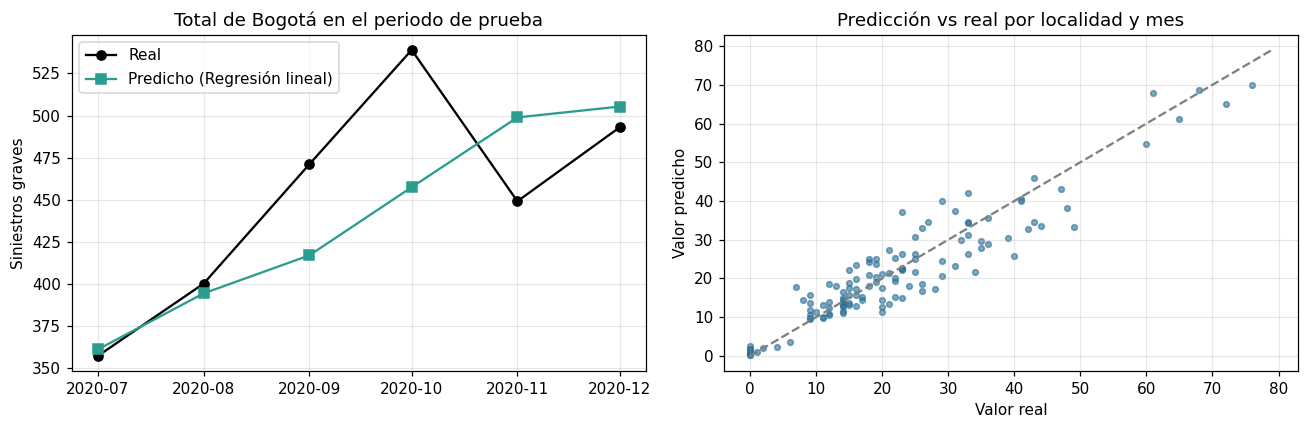

In [11]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
tot = res.groupby("fecha")[[OBJETIVO, "pred"]].sum()
ax[0].plot(tot.index, tot[OBJETIVO], marker="o", label="Real", color="black")
ax[0].plot(tot.index, tot["pred"], marker="s", label=f"Predicho ({mejor})", color="#2a9d8f")
ax[0].set_title("Total de Bogotá en el periodo de prueba"); ax[0].set_ylabel("Siniestros graves"); ax[0].legend()
ax[1].scatter(res[OBJETIVO], res["pred"], s=14, alpha=0.6, color="#2a6f97")
mx = max(res[OBJETIVO].max(), res["pred"].max()) + 3
ax[1].plot([0, mx], [0, mx], "--", color="gray"); ax[1].set_xlabel("Valor real"); ax[1].set_ylabel("Valor predicho")
ax[1].set_title("Predicción vs real por localidad y mes")
plt.tight_layout(); plt.savefig(CARPETA_FIG / "fig_5_predicho_vs_real.png", dpi=150); plt.show()

### 5.3 Variables más importantes (modelo elegido)

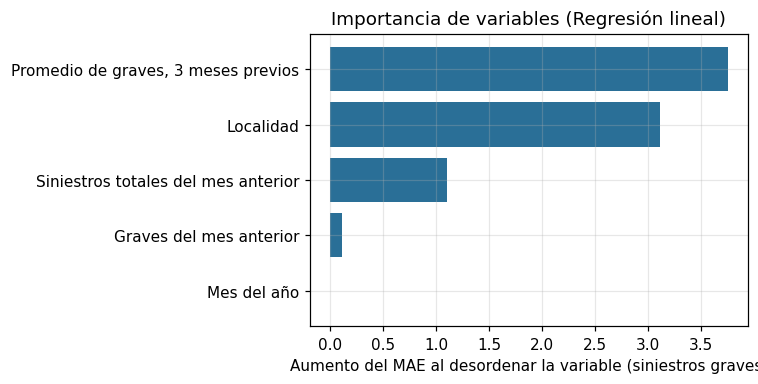

graves_prom_3m         3.76
localidad              3.12
total_mes_anterior     1.10
graves_mes_anterior    0.11
mes                   -0.00

Coeficientes de las variables numericas:
remainder__mes                    0.184
remainder__graves_mes_anterior    0.043
remainder__graves_prom_3m         0.445
remainder__total_mes_anterior     0.072


In [12]:
imp = permutation_importance(modelos[mejor], X_pru, y_pru, scoring="neg_mean_absolute_error",
                             n_repeats=30, random_state=SEMILLA)
importancia = pd.Series(imp.importances_mean, index=X_pru.columns).sort_values()
etiquetas = {"graves_mes_anterior": "Graves del mes anterior", "graves_prom_3m": "Promedio de graves, 3 meses previos",
             "total_mes_anterior": "Siniestros totales del mes anterior", "mes": "Mes del año", "localidad": "Localidad"}
fig, ax = plt.subplots(figsize=(7, 3.6))
ax.barh([etiquetas[i] for i in importancia.index], importancia.values, color="#2a6f97")
ax.set_xlabel("Aumento del MAE al desordenar la variable (siniestros graves)")
ax.set_title(f"Importancia de variables ({mejor})")
plt.tight_layout(); plt.savefig(CARPETA_FIG / "fig_5_3_importancia_variables.png", dpi=150); plt.show()
print(importancia.sort_values(ascending=False).round(2).to_string())
if mejor == "Regresión lineal":
    coef = pd.Series(modelos[mejor].named_steps["modelo"].coef_,
                     index=modelos[mejor].named_steps["pre"].get_feature_names_out())
    print("\nCoeficientes de las variables numericas:")
    print(coef[[c for c in coef.index if c.startswith("remainder__")]].round(3).to_string())

### 5.4 Criterio de éxito

In [13]:
mae_final = float(m_mejor["MAE"])
alcanzo = mae_final < UMBRAL_MAE
print(f"Criterio: MAE < {UMBRAL_MAE:.0f} siniestros graves por localidad y mes")
print(f"Valor obtenido ({mejor}): MAE = {mae_final:.2f}  ->  {'SE ALCANZÓ' if alcanzo else 'NO SE ALCANZÓ'}")
print(f"Referencia en entrenamiento (repetir el mes anterior): MAE = "
      f"{mean_absolute_error(y_ent, X_ent['graves_mes_anterior']):.2f}")

Criterio: MAE < 5 siniestros graves por localidad y mes
Valor obtenido (Regresión lineal): MAE = 4.11  ->  SE ALCANZÓ
Referencia en entrenamiento (repetir el mes anterior): MAE = 6.27


### Prueba de robustez (no cambia el modelo elegido)
Si en lugar de probar con los últimos 6 meses se entrena solo con 2018-2019 y se prueba con todo 2020, el confinamiento (un cambio de régimen que no está en los datos de entrenamiento) deteriora los dos modelos, y el bosque aleatorio se deteriora menos que la regresión lineal. La elección del modelo se mantiene, porque la prueba y el criterio se definieron de antemano sobre los últimos 6 meses, pero se deja a la vista el límite del modelo: ante un cambio brusco como el confinamiento, ninguno de los dos acierta bien.

In [14]:
corte = pd.Timestamp("2020-01-01")
e2, p2 = df[df["fecha"] < corte], df[df["fecha"] >= corte]
filas = []
for nombre, pipe in {"Regresión lineal": armar(LinearRegression()),
                     "Bosque aleatorio": armar(RandomForestRegressor(n_estimators=200, max_depth=8, random_state=SEMILLA, n_jobs=-1))}.items():
    pipe.fit(e2[CAT + NUM], e2[OBJETIVO]); mae, rmse = metricas(p2[OBJETIVO], pipe.predict(p2[CAT + NUM]))
    filas.append([nombre, round(mae, 2), round(rmse, 2)])
print(f"Entrenamiento 2018-2019 ({len(e2)} registros) -> prueba 2020 ({len(p2)} registros)")
pd.DataFrame(filas, columns=["Algoritmo", "MAE", "RMSE"])

Entrenamiento 2018-2019 (420 registros) -> prueba 2020 (240 registros)


,Algoritmo,MAE,RMSE
0,Regresión lineal,8.63,11.72
1,Bosque aleatorio,6.14,8.80


### 5.5 Respuesta a la pregunta de negocio
Se vuelve a ajustar el algoritmo elegido con **todos** los meses disponibles (2018-2020) y se predice el mes siguiente al último dato: enero de 2021, usando como entradas lo ocurrido en octubre-diciembre de 2020.

In [15]:
final = armar(LinearRegression() if mejor == "Regresión lineal"
              else RandomForestRegressor(n_estimators=200, max_depth=8, random_state=SEMILLA, n_jobs=-1))
final.fit(df[CAT + NUM], df[OBJETIVO])

ult = df_bruto[df_bruto["localidad"] != "DESCONOCIDA"].copy()
ult["fecha"] = pd.to_datetime(dict(year=ult["anio"], month=ult["mes"], day=1))
ult = ult.sort_values(["localidad", "fecha"])
filas = []
for loc, g in ult.groupby("localidad"):
    g = g.tail(3)
    filas.append({"localidad": loc, "mes": 1,
                  "graves_mes_anterior": g["siniestros_graves"].iloc[-1],
                  "graves_prom_3m": g["siniestros_graves"].mean(),
                  "total_mes_anterior": g["siniestros_total"].iloc[-1],
                  "graves_dic_2020": g["siniestros_graves"].iloc[-1]})
nuevo = pd.DataFrame(filas)
nuevo["pronostico_ene_2021"] = final.predict(nuevo[CAT + NUM]).clip(min=0).round(1)
pron = nuevo[["localidad", "graves_dic_2020", "pronostico_ene_2021"]].sort_values("pronostico_ene_2021", ascending=False).reset_index(drop=True)
pron.to_csv(CARPETA_MODELO / "pronostico_2021_01.csv", index=False)
print(f"Pronóstico de enero de 2021 para Bogotá: {pron['pronostico_ene_2021'].sum():.0f} siniestros graves (diciembre de 2020: {pron['graves_dic_2020'].sum():.0f}).")
top5 = pron.head(5)
print("Cinco localidades con más siniestros graves esperados:",
      "; ".join(f"{r.localidad} {r.pronostico_ene_2021:.0f}" for r in top5.itertuples()))
print(f"Esas cinco concentran el {top5['pronostico_ene_2021'].sum() / pron['pronostico_ene_2021'].sum():.0%} del total esperado.")
pron.head(10)

Pronóstico de enero de 2021 para Bogotá: 475 siniestros graves (diciembre de 2020: 493).
Cinco localidades con más siniestros graves esperados: KENNEDY 70; SUBA 42; ENGATIVA 42; PUENTE ARANDA 37; BOSA 35
Esas cinco concentran el 47% del total esperado.


,localidad,graves_dic_2020,pronostico_ene_2021
0,KENNEDY,76,69.6
1,SUBA,43,42.3
2,ENGATIVA,41,41.7
3,PUENTE ARANDA,36,36.7
4,BOSA,44,35.3
5,CIUDAD BOLIVAR,39,30.4
6,FONTIBON,26,29.7
7,USAQUEN,23,24.3
8,SAN CRISTOBAL,19,21.9
9,RAFAEL URIBE URIBE,20,19.5


## 6. Despliegue
### 6.1 Tabla de predicciones
`dw/ddl/15_pred_siniestros_graves.sql` crea la tabla `pred_siniestros_graves`. Aquí se genera el contenido (predicciones del modelo elegido sobre el periodo de prueba, con su valor real) como CSV y como script SQL. La carga directa al data warehouse solo ocurre si se define `CARGAR_PRED_DW=1` (ver la última celda).

In [16]:
pred_tabla = pd.DataFrame({
    "sk_tiempo": res["fecha"].dt.strftime("%Y%m%d").astype(int),     # primer dia del mes = llave de dim_tiempo
    "localidad": res["localidad"],
    "valor_real": res[OBJETIVO].astype(int),
    "valor_predicho": res["pred"].round(2),
    "modelo": mejor,
}).sort_values(["sk_tiempo", "localidad"]).reset_index(drop=True)
pred_tabla.to_csv(CARPETA_MODELO / "predicciones.csv", index=False, encoding="utf-8")

def esc(s): return s.replace("'", "''")
lineas = ["-- 16_cargar_pred_siniestros_graves.sql",
          "-- Carga las predicciones del modelo elegido (periodo de prueba) en pred_siniestros_graves.",
          "-- Generado por modelo/modelo_siniestros_graves.ipynb. Ejecutar despues de 15_pred_siniestros_graves.sql.",
          "", "TRUNCATE TABLE dw_siniestros.pred_siniestros_graves;", "",
          "INSERT INTO dw_siniestros.pred_siniestros_graves (sk_tiempo, localidad, valor_real, valor_predicho, modelo) VALUES"]
vals = [f"  ({r.sk_tiempo}, '{esc(r.localidad)}', {r.valor_real}, {r.valor_predicho:.2f}, '{esc(r.modelo)}')" for r in pred_tabla.itertuples()]
lineas.append(",\n".join(vals) + ";")
(CARPETA_DDL / "16_cargar_pred_siniestros_graves.sql").write_text("\n".join(lineas) + "\n", encoding="utf-8")
print("Filas de la tabla de predicciones:", len(pred_tabla), "| Archivos: predicciones.csv y 16_cargar_pred_siniestros_graves.sql")
pred_tabla.head()

Filas de la tabla de predicciones: 120 | Archivos: predicciones.csv y 16_cargar_pred_siniestros_graves.sql


,sk_tiempo,localidad,valor_real,valor_predicho,modelo
0,20200701,ANTONIO NARINO,11,9.73,Regresión lineal
1,20200701,BARRIOS UNIDOS,14,11.17,Regresión lineal
2,20200701,BOSA,18,25.00,Regresión lineal
3,20200701,CANDELARIA,0,2.45,Regresión lineal
4,20200701,CHAPINERO,9,9.44,Regresión lineal


In [17]:
# Carga opcional directa al data warehouse (requiere haber ejecutado antes el script 15 y definir las variables de entorno)
if os.getenv("CARGAR_PRED_DW") == "1":
    from sqlalchemy import create_engine, text
    from sqlalchemy.engine import URL
    motor = create_engine(URL.create("mysql+pymysql", username=os.environ["DW_USER"], password=os.environ["DW_PASSWORD"],
                                     host=os.getenv("DW_HOST", "localhost"), port=int(os.getenv("DW_PORT", "3306")),
                                     database=os.getenv("DW_DB", "dw_siniestros")))
    with motor.begin() as con:
        con.execute(text("TRUNCATE TABLE pred_siniestros_graves"))
        pred_tabla.to_sql("pred_siniestros_graves", con, if_exists="append", index=False)
        print("Filas cargadas:", con.execute(text("SELECT COUNT(*) FROM pred_siniestros_graves")).scalar())
else:
    print("Carga directa omitida (definir CARGAR_PRED_DW=1 para activarla). Alternativa: ejecutar dw/ddl/16_cargar_pred_siniestros_graves.sql.")

Carga directa omitida (definir CARGAR_PRED_DW=1 para activarla). Alternativa: ejecutar dw/ddl/16_cargar_pred_siniestros_graves.sql.
